# Rwanda Youth Employment — Complete ML Diagnostics with PyCaret
### LFS 2025 | Project-based learning | Teaching and analysis notebook

**Research question:** How well can observable characteristics classify **employed vs. unemployed** young people (ages 16–30) **among those in the labour force** in Rwanda?

This notebook was developed from your original `ml.ipynb` and the corrected five-model comparison. It deliberately avoids `neet_status`, job-sector, employment income, and other target-revealing fields.

**What you will learn:** data audit → leakage audit → missingness → training/holdout split → cross-validation → model comparison → minority-class diagnostics → ROC/PR and calibration → error analysis → feature importance → robustness checks → responsible reporting.

> **Version:** This notebook uses **PyCaret 3.x** (the functional API shown in your screenshots). PyCaret 4.x has a changed API. The version check below prevents confusing errors.  
> **Data:** There is no LFS data bundled in this notebook. Set the Excel path in Section 2 and run the cells in order.  
> **Inference:** Your 21-column Excel export has no survey weights/PSU/strata. These are exploratory **unweighted predictive** results, not official Rwanda unemployment statistics or causal determinants.

## Roadmap

| Stage | Why we need it | Main result |
|---|---|---|
| 1. Verify tools | Confirm the version and scientific packages | Reproducibility |
| 2. Audit the data | Avoid leakage and wrong population | Defensible predictors |
| 3. Understand missingness | Distinguish missing from not applicable | No premature filling |
| 4. Set up PyCaret | Fit cleaning **inside** training/CV | Proper evaluation |
| 5. Compare models | Use AUC, not accuracy alone | Training-fold scores |
| 6. Diagnose test results | Focus on **Unemployed** class | Precision, recall, F1, MCC, etc. |
| 7. Check probabilities | ROC, PR, Brier, calibration | Ranking and reliability |
| 8. Understand errors | Which individuals/groups are missed? | Practical limitations |
| 9. Explain the model | Importance without causal claims | Report discussion |
| 10. Optional experiments | Tuning and imbalance strategies | Training-only comparisons |
| 11. Report checklist | What to write and what not to claim | PBL submission |

**Interpretation guide:** A high **accuracy** may only mean the classifier predicts the much more common `Employed` class. Throughout this notebook, **Unemployed = positive class (1)** for manual diagnostic metrics.

## 1. Packages and version check

In [134]:
import sys
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    classification_report, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score,
    matthews_corrcoef, cohen_kappa_score, log_loss,
    brier_score_loss, RocCurveDisplay, PrecisionRecallDisplay
)

import pycaret
from pycaret.classification import (
    setup, get_config, compare_models, create_model, pull,
    predict_model, plot_model, tune_model, optimize_threshold,
    finalize_model, save_model
)

print("Python:", sys.version.split()[0])
print("PyCaret:", importlib.metadata.version("pycaret"))
print("Pandas:", pd.__version__)

if not importlib.metadata.version("pycaret").startswith("3."):
    raise RuntimeError("This notebook expects PyCaret 3.x. The PyCaret 4 API differs.")

Python: 3.11.9
PyCaret: 3.3.2
Pandas: 2.1.4


### Vocabulary before starting

- **Outcome / target:** `employment_status` (Employed vs Unemployed).
- **Predictor / feature:** Information available *before* determining the target, e.g. age, education, location.
- **Leakage:** A feature directly or indirectly contains the outcome we want to predict.
- **Imputation:** A method for filling missing values. **Fit imputation on training folds**, never on all records before the split.
- **Cross-validation (CV):** Repeatedly assess models on different parts of the training sample.
- **Holdout set:** The final test set, kept out of training, model choice, and threshold choice.

## 2. Load your cleaned Excel export

In [135]:
# Use the same file path as in your original ml.ipynb.
path = r"C:\Users\branc\OneDrive\Documenti\Academia\Year 4\Machine Learning\Assignments\PBL 1\Data\Cleaned Dataset.xlsx"

from pathlib import Path
if not Path(path).is_file():
    raise FileNotFoundError("Update 'path' to the location of your Cleaned Dataset.xlsx file.")

lfs = pd.read_excel(path)
print("Raw export dimensions:", lfs.shape)
print("Columns:", lfs.columns.tolist())
display(lfs.head(3))

Raw export dimensions: (15961, 21)
Columns: ['employment_status', 'age', 'sex', 'education_level', 'current_student', 'residence', 'province', 'marital_status', 'years_of_schooling', 'tvet_training', 'disability_indicator', 'household_size_group', 'household_relationship', 'district', 'activity_after_tvet', 'time_to_job_after_tvet', 'neet_status', 'time_underemployment', 'formal_informal_work', 'employment_sector', 'income_cash']


,employment_status,age,sex,education_level,current_student,residence,province,marital_status,years_of_schooling,tvet_training,...,household_size_group,household_relationship,district,activity_after_tvet,time_to_job_after_tvet,neet_status,time_underemployment,formal_informal_work,employment_sector,income_cash
0,Employed,19,Male,Upper secondary,No,Urban,City of Kigali,Single,12.0,Yes,...,9 persons,Child (Son/daughter),Nyarugenge,Nothing,NaN,Not NEET,Not time related underemployed,Informal employment,Services,NaN
1,Employed,20,Female,Primary,No,Urban,City of Kigali,Single,8.0,Yes,...,4 Persons,Child (Son/daughter),Nyarugenge,Nothing,NaN,Not NEET,Not time related underemployed,Informal employment,Services,39000.0
2,Employed,30,Female,Primary,No,Urban,City of Kigali,Single,6.0,No,...,1 person,Household Head,Nyarugenge,NaN,NaN,Not NEET,Time related underemployed,Informal employment,Services,39000.0


**Critical note about your earlier R work:** In `EDA_2.pdf`, you replaced missing `years_of_schooling` values with their mean. If the Excel file was saved **after** that operation, the original missing values cannot be recovered from this export. For the strictest comparison, export again from your pre-imputation `.rds`/`.dta` source before running this notebook. The audit below can only check missing values that are still present.

## 3. Define a leakage-free analysis dataset

In [136]:
# These columns are retained because they are observable across employed
# and unemployed youth, subject to the original questionnaire.
predictors = [
    "age", "sex", "education_level", "current_student",
    "residence", "province", "marital_status",
    "years_of_schooling", "tvet_training", "disability_indicator",
    "household_size_group", "household_relationship", "district"
]

target = "employment_status"
required = [target] + predictors
missing_columns = sorted(set(required) - set(lfs.columns))
if missing_columns:
    raise KeyError(f"Missing columns in Excel file: {missing_columns}")

model_data = lfs[required].copy()
model_data = model_data.dropna(subset=[target])
model_data[target] = model_data[target].astype(str).str.strip()
model_data = model_data.loc[model_data[target].isin(["Employed", "Unemployed"])].copy()

print("Analysis dimensions:", model_data.shape)
print(model_data[target].value_counts())
assert set(model_data[target].unique()) == {"Employed", "Unemployed"}
display(model_data.head(3))

Analysis dimensions: (15961, 14)
employment_status
Employed      13608
Unemployed     2353
Name: count, dtype: int64


,employment_status,age,sex,education_level,current_student,residence,province,marital_status,years_of_schooling,tvet_training,disability_indicator,household_size_group,household_relationship,district
0,Employed,19,Male,Upper secondary,No,Urban,City of Kigali,Single,12.0,Yes,0,9 persons,Child (Son/daughter),Nyarugenge
1,Employed,20,Female,Primary,No,Urban,City of Kigali,Single,8.0,Yes,0,4 Persons,Child (Son/daughter),Nyarugenge
2,Employed,30,Female,Primary,No,Urban,City of Kigali,Single,6.0,No,0,1 person,Household Head,Nyarugenge


### Variables **intentionally excluded** from employment prediction

| Variable | Why not use it as a predictor? |
|---|---|
| `neet_status` | **NEET includes non-employment in its definition**; this is target leakage. |
| `employment_sector`, `formal_informal_work` | Recorded only for people already employed; **not applicable** for the unemployed. |
| `time_underemployment` | Defined among employed workers. |
| `income_cash`, `income_status` | Cash income/availability is partly tied to already being employed; additionally, missing is not equal to zero income. |
| `activity_after_tvet`, `time_to_job_after_tvet` | Post-training outcomes can reveal whether a person has found work. |
| `survey_weight`, IDs/PSU, sample strata | Survey design fields are **not employment predictors**. Save them separately for a design-aware analysis. |

**Scope reminder:** This is a binary model **conditional on participation in the labour force**. It is **not** a three-category model for all young people and cannot predict participation or actual school-to-work durations. Age 16–30 and LFS eligibility have already been selected in your cleaned export; verify this against your raw LFS file.

## 4. Missing values — inspect before filling

In [137]:
missing_table = pd.DataFrame({
    "missing_n": model_data.isna().sum(),
    "missing_percent": 100 * model_data.isna().mean()
}).sort_values("missing_percent", ascending=False)

display(missing_table.round(2))

# Compare missingness in TVET between employed and unemployed youth.
display(pd.crosstab(
    model_data[target],
    model_data["tvet_training"].isna(),
    margins=True
))

,missing_n,missing_percent
education_level,5658,35.45
tvet_training,558,3.50
years_of_schooling,2,0.01
employment_status,0,0.00
age,0,0.00
sex,0,0.00
current_student,0,0.00
residence,0,0.00
province,0,0.00
marital_status,0,0.00


tvet_training,False,True,All
employment_status,,,
Employed,13157,451,13608
Unemployed,2246,107,2353
All,15403,558,15961


**Why do not impute here?** Mean or mode filling on the entire dataset uses information from the future holdout. `setup()` below builds a training-aware preprocessing pipeline. 

- **Ordinary missingness:** A response should exist but is absent; imputation may be reasonable.
- **Structural missingness:** A question was not asked because it was inapplicable. Do not invent an answer.
- **TVET:** Check the questionnaire routing for the 558 missing values seen in your earlier EDA. If they result from skips, review that variable's eligibility and consider a sensitivity analysis (rather than automatically calling them "No").

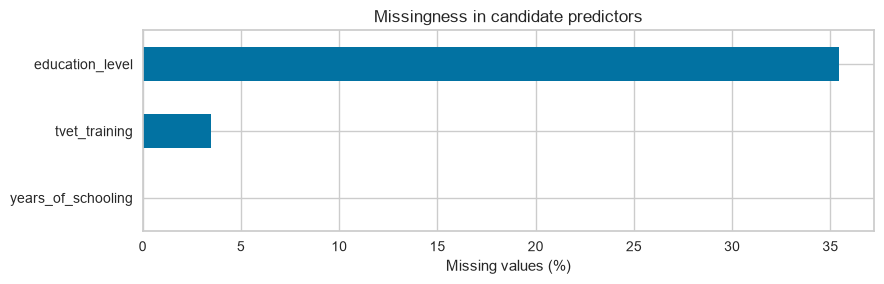

In [138]:
# Note: This chart is descriptive; it is not a modeling step.
missing_pct = missing_table.query("missing_n > 0")["missing_percent"]
if len(missing_pct) > 0:
    plt.figure(figsize=(9, max(3, 0.45 * len(missing_pct))))
    missing_pct.sort_values().plot(kind="barh")
    plt.xlabel("Missing values (%)")
    plt.title("Missingness in candidate predictors")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values remain in the selected export. Check whether imputation was already performed in R.")

## 5. Baseline: why accuracy can mislead

In [139]:
class_counts = model_data[target].value_counts()
majority_accuracy = 100 * class_counts.max() / class_counts.sum()
unemployment_share = 100 * (model_data[target] == "Unemployed").mean()

print(f"Majority-class baseline accuracy: {majority_accuracy:.2f}%")
print(f"Unemployed share of this sample: {unemployment_share:.2f}%")
print("A model predicting everyone 'Employed' would have 0% recall for the unemployed.")

Majority-class baseline accuracy: 85.26%
Unemployed share of this sample: 14.74%
A model predicting everyone 'Employed' would have 0% recall for the unemployed.


A **dummy majority classifier** can achieve approximately the employed share of the sample with **no ability to detect unemployment**. Always compare your best model against this baseline. The sample percentages here are **unweighted**.

## 6. Initialize PyCaret correctly

In [140]:
exp = setup(
    data=model_data,
    target="employment_status",
    session_id=123,
    train_size=0.70,
    data_split_stratify=True,
    fold_strategy="stratifiedkfold",
    fold=5,
    preprocess=True,
    imputation_type="simple",
    numeric_imputation="median",
    categorical_imputation="mode",
    fix_imbalance=False,
    normalize=False,
    html=True
)

,Description,Value
0,Session id,123
1,Target,employment_status
2,Target type,Binary
3,Target mapping,"Employed: 0, Unemployed: 1"
4,Original data shape,"(15961, 14)"
5,Transformed data shape,"(15961, 47)"
6,Transformed train set shape,"(11172, 47)"
7,Transformed test set shape,"(4789, 47)"
8,Numeric features,3
9,Categorical features,10


### What PyCaret is doing

1. Holds back **30%** of the dataset, without using it to fit models.
2. Uses **stratified** splitting so both classes remain represented.
3. Performs median/mode imputation and categorical encoding **in its training preprocessing pipeline**.
4. Compares algorithms with **five-fold CV on the 70% training portion**.

**Why not scale now?** Tree-based models do not require scaling. If you later compare distance-based methods like KNN/SVM, run a *separate setup with scaling inside CV*, not a pre-split scaler.

In [141]:
x_train = get_config("X_train")
x_holdout = get_config("X_test")
y_train = get_config("y_train")
y_holdout = get_config("y_test")

print("Training rows:", len(x_train))
print("Untouched holdout rows:", len(x_holdout))
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nHoldout class proportions:")
print(y_holdout.value_counts(normalize=True).round(3))

Training rows: 11172
Untouched holdout rows: 4789

Training class proportions:
employment_status
Employed      0.853
Unemployed    0.147
Name: proportion, dtype: float64

Holdout class proportions:
employment_status
Employed      0.853
Unemployed    0.147
Name: proportion, dtype: float64


**Survey-design limitation:** A random individual-level split can place individuals from the same household or survey cluster on both sides, creating overly optimistic evaluation. The export has no PSU/household identifiers. For the final report, request a new export containing `weight2` and survey identifiers, then consider a grouped validation strategy and design-weighted performance. PyCaret's normal accuracy/AUC is not automatically population-weighted.

## 7. Compare models using training-fold cross-validation

In [142]:
best = compare_models(
    include=["dummy", "lr", "rf", "et", "gbc", "dt"],
    sort="AUC",
    fold=5
)

cv_results = pull().copy()
display(cv_results)
print("Chosen estimator:", best)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.8517,0.6845,0.8517,0.7931,0.7866,0.0099,0.0379,0.5020
rf,Random Forest Classifier,0.8400,0.6746,0.8400,0.7960,0.8079,0.1428,0.1640,0.5640
lr,Logistic Regression,0.8526,0.6712,0.8526,0.7269,0.7847,0.0000,0.0000,0.7140
et,Extra Trees Classifier,0.8258,0.6577,0.8258,0.7905,0.8037,0.1483,0.1571,0.4900
dt,Decision Tree Classifier,0.7789,0.5706,0.7789,0.7823,0.7805,0.1336,0.1337,0.1840
dummy,Dummy Classifier,0.8526,0.5000,0.8526,0.7269,0.7847,0.0000,0.0000,0.4300


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.8517,0.6845,0.8517,0.7931,0.7866,0.0099,0.0379,0.502
rf,Random Forest Classifier,0.8400,0.6746,0.8400,0.7960,0.8079,0.1428,0.1640,0.564
lr,Logistic Regression,0.8526,0.6712,0.8526,0.7269,0.7847,0.0000,0.0000,0.714
et,Extra Trees Classifier,0.8258,0.6577,0.8258,0.7905,0.8037,0.1483,0.1571,0.490
dt,Decision Tree Classifier,0.7789,0.5706,0.7789,0.7823,0.7805,0.1336,0.1337,0.184
dummy,Dummy Classifier,0.8526,0.5000,0.8526,0.7269,0.7847,0.0000,0.0000,0.430


Chosen estimator: GradientBoostingClassifier(ccp_alpha=0.0, criterion='friedman_mse', init=None,
                           learning_rate=0.1, loss='log_loss', max_depth=3,
                           max_features=None, max_leaf_nodes=None,
                           min_impurity_decrease=0.0, min_samples_leaf=1,
                           min_samples_split=2, min_weight_fraction_leaf=0.0,
                           n_estimators=100, n_iter_no_change=None,
                           random_state=123, subsample=1.0, tol=0.0001,
                           validation_fraction=0.1, verbose=0,
                           warm_start=False)


### Read the comparison correctly

- **Accuracy:** Overall share correctly classified; heavily influenced by Employed majority.
- **AUC (ROC-AUC):** Ranking ability over thresholds; 0.5 ≈ random ranking.
- **Recall, Precision, F1:** PyCaret's displayed summary may **not** use `Unemployed` as the focal positive class. Do **not** assume the headline Recall is unemployment recall.
- **Kappa / MCC:** Agreement/correlation beyond a simple accuracy view; useful in imbalanced samples.
- **CV summary:** Training-fold means, **not** the final holdout result.

**Our primary conclusions will come from explicit `Unemployed`-class metrics on holdout.** Keep the full CV leaderboard (including the dummy) for the report.

In [143]:
# Save training CV scores for your later report.
cv_results.to_csv("PyCaret_training_CV_comparison.csv")
print("Saved: PyCaret_training_CV_comparison.csv")

Saved: PyCaret_training_CV_comparison.csv


## 8. Optional: inspect a few key benchmark models

In [144]:
# OPTIONAL: Uncomment only if you want named estimators for separate diagnostics.
# Training these takes extra time; compare_models() already evaluates them by CV.
# lr_model = create_model("lr")
# rf_model = create_model("rf")
# gbc_model = create_model("gbc")
# dummy_model = create_model("dummy")

**What is the difference?** Logistic Regression is a transparent linear benchmark; Random Forest and Gradient Boosting capture more complex patterns; Dummy is a sanity check. Creating named estimators also makes it easy to compare their confusion matrices later.

## 9. Core PyCaret diagnostic plots — run one cell at a time

The following PyCaret 3 charts generally use the **holdout** data. Treat them as **diagnostic descriptions of the fixed selected model**, not as a reason to repeatedly pick new models using the holdout. Plots may be computationally expensive; run the cells individually.

**Read the chart first; then read the interpretation below it.**

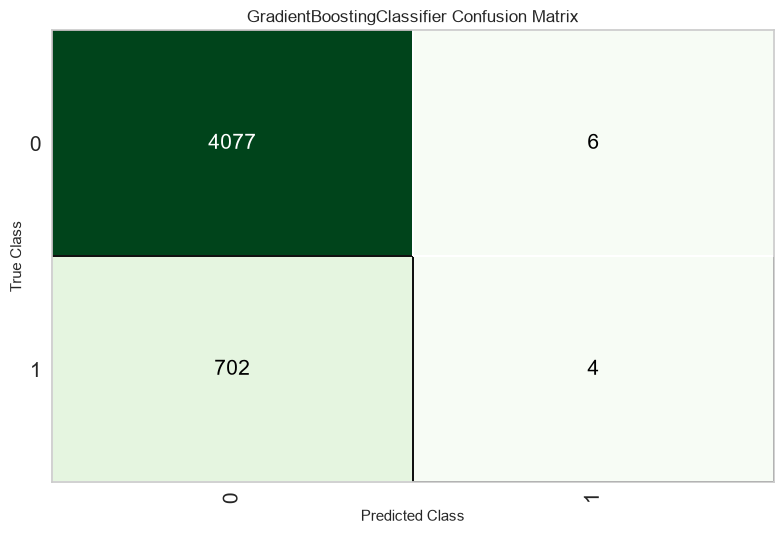

In [145]:
plot_model(best, plot="confusion_matrix")

**Confusion matrix:** Count **TP** (unemployed correctly flagged), **FN** (unemployed missed), **FP** (employed incorrectly flagged), and **TN** (employed correctly classified). The positive class for the manual metrics below is *Unemployed*; PyCaret's plot axis ordering may differ.

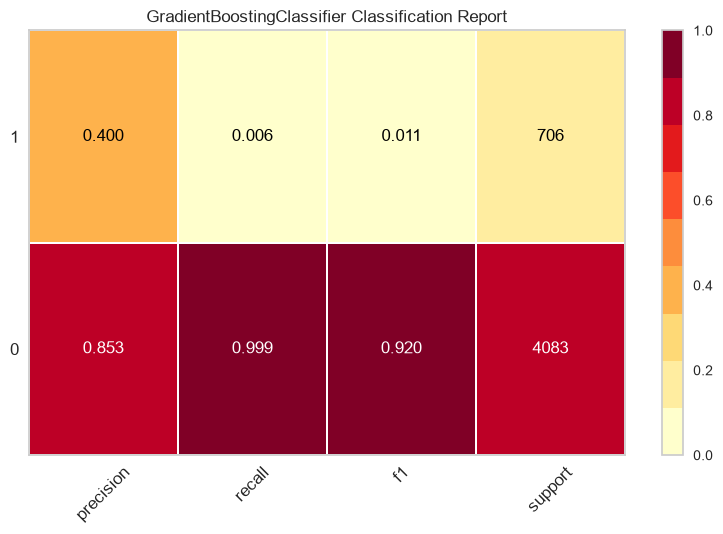

In [146]:
plot_model(best, plot="class_report")

**Classification report:** Compare recall and precision **separately for Employed and Unemployed**. A single weighted-average F1 can hide poor minority-class performance.

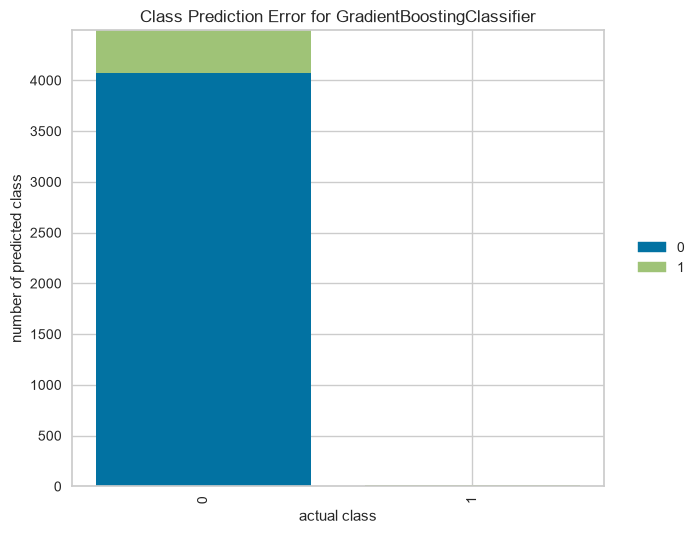

In [147]:
plot_model(best, plot="error")

**Class prediction error:** A visual summary of where class assignments are correct or confused.

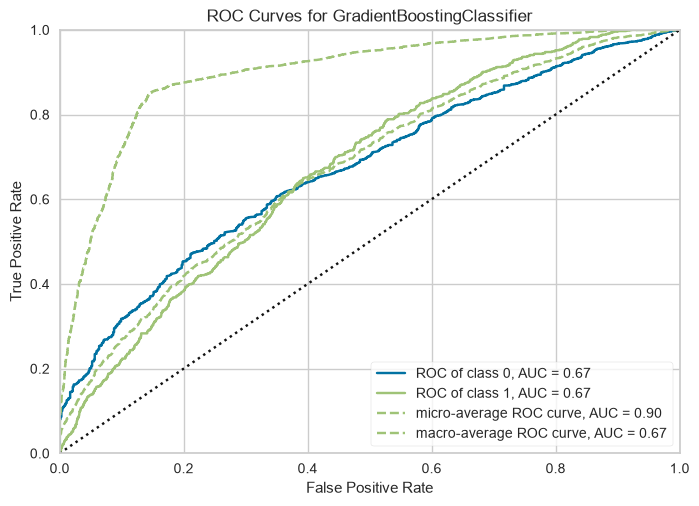

In [148]:
plot_model(best, plot="auc")

**ROC curve:** True-positive rate versus false-positive rate across thresholds. AUC measures ranking, not whether 0.5 is an appropriate decision threshold.

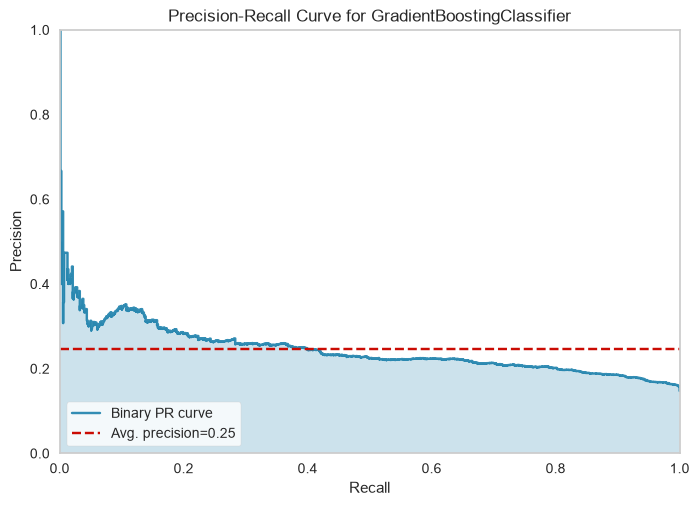

In [149]:
plot_model(best, plot="pr")

**Precision–Recall curve:** Often more informative when unemployed people are a minority. Compare average precision with unemployment prevalence.

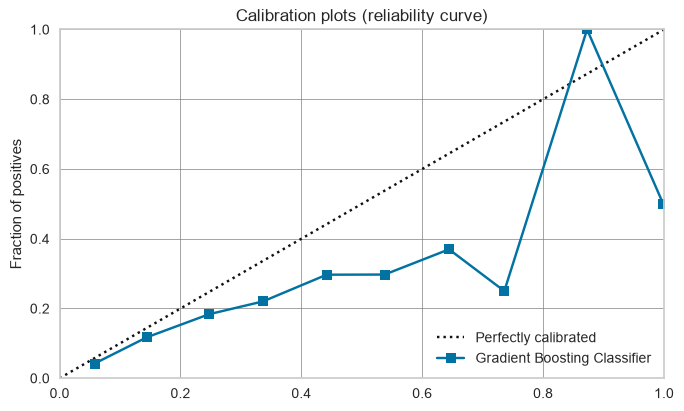

In [150]:
plot_model(best, plot="calibration")

**Calibration curve:** Among respondents assigned a 20% probability of unemployment, about 20% should actually be unemployed, approximately, if the model is calibrated. Ranking and calibration are different.

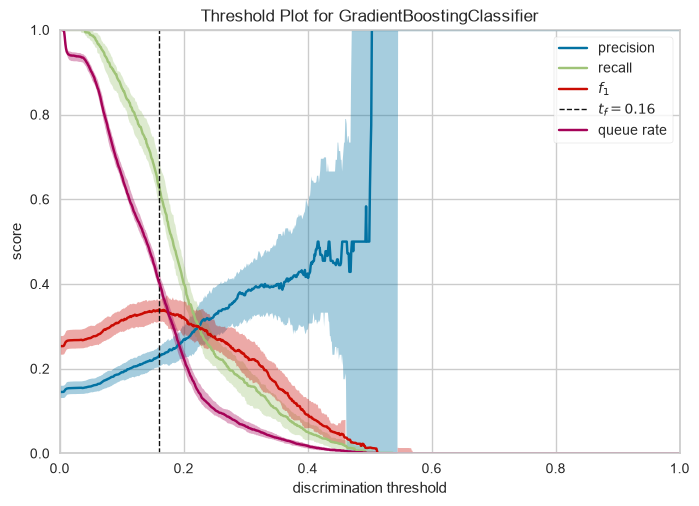

In [151]:
plot_model(best, plot="threshold")

**Threshold plot:** Different decision cutoffs trade off finding more unemployed people against incorrectly flagging employed people. Do not choose the cutoff based on final holdout performance.

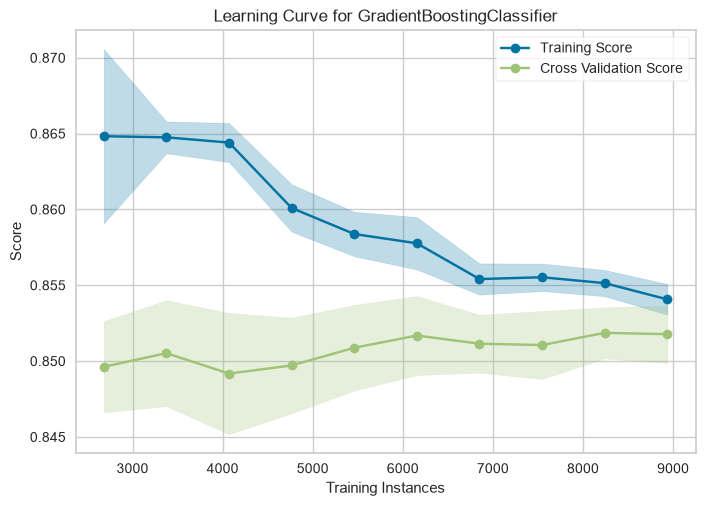

In [152]:
plot_model(best, plot="learning")

**Learning curve:** Compare performance with more training records. A large training–validation gap suggests overfitting; both curves low suggests limited predictive information.

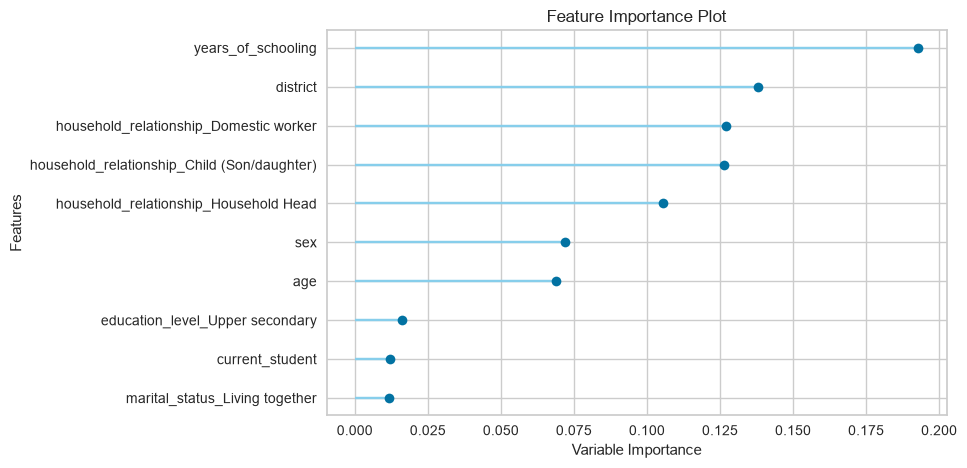

In [153]:
plot_model(best, plot="feature")

**Feature importance:** Relative contribution to predictions in the fitted tree-based model. Importance does **not** prove a causal determinant. Correlated predictors share/reallocate importance.

### Further available PyCaret 3 plot IDs (optional)

Run these individually if useful and supported for the chosen estimator:

- `plot_model(best, plot="feature_all")` — all importance scores
- `plot_model(best, plot="lift")` — enrichment when ranking people by predicted risk
- `plot_model(best, plot="gain")` — cumulative gains
- `plot_model(best, plot="ks")` — separation between predicted score distributions
- `plot_model(best, plot="parameter")` — model hyperparameters
- `plot_model(best, plot="pipeline")` — preprocessing workflow (if supported by your minor version)

Some PyCaret charts require more memory, estimator-specific attributes, or extra plotting dependencies. **Not every diagnostic is valid or necessary for every model.** The manual checks below remain available if a PyCaret plot fails.

## 10. Evaluate the chosen model on the untouched holdout

In [154]:
# raw_score=True returns a probability for EACH class.
# This is important: 'prediction_score' alone is the probability of the PREDICTED class,
# NOT necessarily the probability of unemployment.
holdout = predict_model(best, raw_score=True)

print("Prediction columns:", holdout.columns.tolist())
display(holdout.head(3))

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Gradient Boosting Classifier,0.8522,0.6727,0.8522,0.7863,0.7861,0.0071,0.0326


Prediction columns: ['age', 'sex', 'education_level', 'current_student', 'residence', 'province', 'marital_status', 'years_of_schooling', 'tvet_training', 'disability_indicator', 'household_size_group', 'household_relationship', 'district', 'employment_status', 'prediction_label', 'prediction_score_Employed', 'prediction_score_Unemployed']


,age,sex,education_level,current_student,residence,province,marital_status,years_of_schooling,tvet_training,disability_indicator,household_size_group,household_relationship,district,employment_status,prediction_label,prediction_score_Employed,prediction_score_Unemployed
6306,28,Male,Lower secondary,No,Urban,Western Province,Single,9.0,Yes,0,2 persons,Household Head,Rusizi,Employed,Employed,0.9188,0.0812
2250,23,Female,Primary,No,Rural,Southern Province,Single,6.0,Yes,0,5Persons,Adopted/Foster/step child,Kamonyi,Employed,Employed,0.8959,0.1041
13422,19,Male,Primary,No,Urban,Western Province,Single,7.0,No,0,7 persons,Child (Son/daughter),Rubavu,Unemployed,Employed,0.8605,0.1395


**Check the probability column carefully.** For the string-labeled dataset, PyCaret typically creates `prediction_score_Unemployed`. Some minor versions may use encoded column names. This notebook recognizes the string label or the `1` column (where Employed=0, Unemployed=1); if neither exists, it stops instead of quietly using the wrong probability.

In [155]:
# Positive class = Unemployed (1). Verify your actual returned labels.
true_status = holdout["employment_status"].astype(str).str.strip()
predicted_status = holdout["prediction_label"].astype(str).str.strip()

assert set(true_status.unique()).issubset({"Employed", "Unemployed"})
assert set(predicted_status.unique()).issubset({"Employed", "Unemployed"})

y_true = (true_status == "Unemployed").astype(int)
y_pred = (predicted_status == "Unemployed").astype(int)

if "prediction_score_Unemployed" in holdout.columns:
    positive_score_column = "prediction_score_Unemployed"
elif "prediction_score_1" in holdout.columns:
    positive_score_column = "prediction_score_1"
else:
    raise KeyError(
        "Unemployed probability column not identified. Print holdout.columns "
        "and confirm the class mapping before continuing."
    )

p_unemployed = holdout[positive_score_column].astype(float)

print("Using positive-class probability:", positive_score_column)
print("Actual label counts:\n", true_status.value_counts())
print("Predicted label counts:\n", predicted_status.value_counts())
print("Probability range:", p_unemployed.min(), "to", p_unemployed.max())

Using positive-class probability: prediction_score_Unemployed
Actual label counts:
 employment_status
Employed      4083
Unemployed     706
Name: count, dtype: int64
Predicted label counts:
 prediction_label
Employed      4779
Unemployed      10
Name: count, dtype: int64
Probability range: 0.0031 to 0.7061


## 11. All main confusion-matrix and class-specific measures

In [156]:
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

counts = pd.DataFrame({
    "Meaning": [
        "Unemployed correctly identified",
        "Unemployed missed",
        "Employed incorrectly flagged",
        "Employed correctly identified"
    ],
    "Count": [tp, fn, fp, tn]
}, index=["TP", "FN", "FP", "TN"])
display(counts)

print("Confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual Employed", "Actual Unemployed"],
    columns=["Predicted Employed", "Predicted Unemployed"]
))

,Meaning,Count
TP,Unemployed correctly identified,4
FN,Unemployed missed,702
FP,Employed incorrectly flagged,6
TN,Employed correctly identified,4077


Confusion matrix (rows=true, columns=predicted):


,Predicted Employed,Predicted Unemployed
Actual Employed,4077,6
Actual Unemployed,702,4


In [157]:
# Each formula uses Unemployed as the POSITIVE class.
metrics = pd.Series({
    "Accuracy": accuracy_score(y_true, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
    "Precision (unemployed)": precision_score(y_true, y_pred, zero_division=0),
    "Recall / sensitivity (unemployed)": recall_score(y_true, y_pred, zero_division=0),
    "Specificity (employed)": tn / (tn + fp) if (tn + fp) > 0 else np.nan,
    "F1 (unemployed)": f1_score(y_true, y_pred, zero_division=0),
    "F2 (unemployed; recall priority)": fbeta_score(y_true, y_pred, beta=2, zero_division=0),
    "Negative predictive value": tn / (tn + fn) if (tn + fn) > 0 else np.nan,
    "False positive rate": fp / (fp + tn) if (fp + tn) > 0 else np.nan,
    "False negative rate": fn / (fn + tp) if (fn + tp) > 0 else np.nan,
    "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
    "Matthews correlation coefficient": matthews_corrcoef(y_true, y_pred),
    "Geometric mean (sens. & spec.)": np.sqrt(
        (tp / (tp + fn)) * (tn / (tn + fp))
    ) if (tp + fn) > 0 and (tn + fp) > 0 else np.nan,
    "ROC AUC": roc_auc_score(y_true, p_unemployed),
    "Average precision / PR-AUC summary": average_precision_score(y_true, p_unemployed),
    "Log loss (lower is better)": log_loss(y_true, p_unemployed, labels=[0, 1]),
    "Brier score (lower is better)": brier_score_loss(y_true, p_unemployed),
    "Actual unemployed prevalence": y_true.mean(),
    "Predicted unemployed proportion": y_pred.mean()
})

display(metrics.to_frame("Holdout value").round(4))
metrics.to_csv("PyCaret_holdout_metrics.csv", header=["holdout_value"])
print("Saved: PyCaret_holdout_metrics.csv")

,Holdout value
Accuracy,0.8522
Balanced accuracy,0.5021
Precision (unemployed),0.4000
Recall / sensitivity (unemployed),0.0057
Specificity (employed),0.9985
F1 (unemployed),0.0112
F2 (unemployed; recall priority),0.0071
Negative predictive value,0.8531
False positive rate,0.0015
False negative rate,0.9943


Saved: PyCaret_holdout_metrics.csv


### Interpret the measures, small-small

| Measure | Question it answers | What is better? |
|---|---|---|
| Accuracy | What fraction of *everyone* was classified correctly? | Higher, but can mislead |
| **Unemployed recall** | Of all truly unemployed young people, how many were found? **TP / (TP+FN)** | Higher |
| **Unemployed precision** | Of those flagged unemployed, how many really are? **TP / (TP+FP)** | Higher |
| **Unemployed F1** | Balance between unemployed precision and recall | Higher |
| F2 | Gives recall more weight than precision | Higher |
| Specificity | Of all employed people, how many were correctly not flagged? | Higher |
| FPR | Of employed people, what fraction were mistakenly flagged unemployed? | Lower |
| FNR | Of unemployed people, what fraction did the model miss? | Lower |
| Balanced accuracy | Average of sensitivity and specificity | Higher |
| MCC | A balanced correlation-based classification score; ranges from −1 to +1 | Closer to +1 |
| Kappa | Agreement beyond chance given the class proportions | Higher |
| ROC-AUC | Does the model rank unemployed above employed reasonably well? | Higher |
| **Average precision** | Does ranking focus on actually unemployed people? Compare to prevalence | Higher |
| Log loss | How badly do probabilities penalize confident wrong predictions? | Lower |
| Brier score | Average squared error of predicted unemployment probability | Lower |

**Caution:** `average_precision_score` is not numerically identical to the trapezoidal area under a plotted PR curve in all implementations. State which you use. The proportion of unemployed youth is a useful **average precision baseline**.

In [158]:
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Employed", "Unemployed"],
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

    Employed      0.853     0.999     0.920      4083
  Unemployed      0.400     0.006     0.011       706

    accuracy                          0.852      4789
   macro avg      0.627     0.502     0.466      4789
weighted avg      0.786     0.852     0.786      4789



### Sanity check: does it beat a model that predicts everybody as employed?

In [159]:
dummy_pred = np.zeros(len(y_true), dtype=int)

baseline_table = pd.DataFrame({
    "Always predict Employed": [
        accuracy_score(y_true, dummy_pred),
        balanced_accuracy_score(y_true, dummy_pred),
        recall_score(y_true, dummy_pred, zero_division=0),
        precision_score(y_true, dummy_pred, zero_division=0),
        f1_score(y_true, dummy_pred, zero_division=0),
        matthews_corrcoef(y_true, dummy_pred)
    ],
    "Selected model": [
        accuracy_score(y_true, y_pred),
        balanced_accuracy_score(y_true, y_pred),
        recall_score(y_true, y_pred, zero_division=0),
        precision_score(y_true, y_pred, zero_division=0),
        f1_score(y_true, y_pred, zero_division=0),
        matthews_corrcoef(y_true, y_pred)
    ]
}, index=["Accuracy", "Balanced accuracy", "Unemployed recall",
          "Unemployed precision", "Unemployed F1", "MCC"])

display(baseline_table.round(4))

,Always predict Employed,Selected model
Accuracy,0.8526,0.8522
Balanced accuracy,0.5000,0.5021
Unemployed recall,0.0000,0.0057
Unemployed precision,0.0000,0.4000
Unemployed F1,0.0000,0.0112
MCC,0.0000,0.0326


**Decision rule for reporting:** If the chosen model only barely beats this baseline, report its limitations clearly—even if its raw accuracy looks high. A model may still have moderate AUC and thus be useful for **ranking risk**, but a fixed 0.5 threshold might not identify many unemployed youth.

## 12. Independent ROC, Precision–Recall, and calibration curves

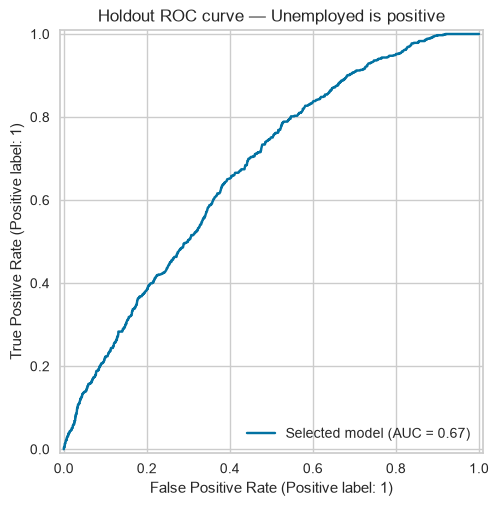

In [160]:
RocCurveDisplay.from_predictions(y_true, p_unemployed, name="Selected model")
plt.title("Holdout ROC curve — Unemployed is positive")
plt.show()

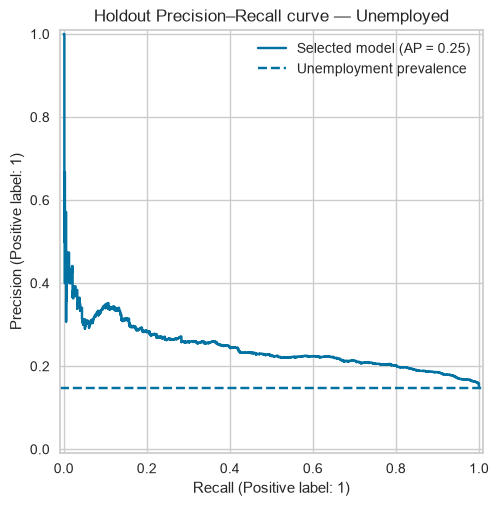

In [161]:
PrecisionRecallDisplay.from_predictions(y_true, p_unemployed, name="Selected model")
plt.axhline(y_true.mean(), linestyle="--", label="Unemployment prevalence")
plt.legend()
plt.title("Holdout Precision–Recall curve — Unemployed")
plt.show()

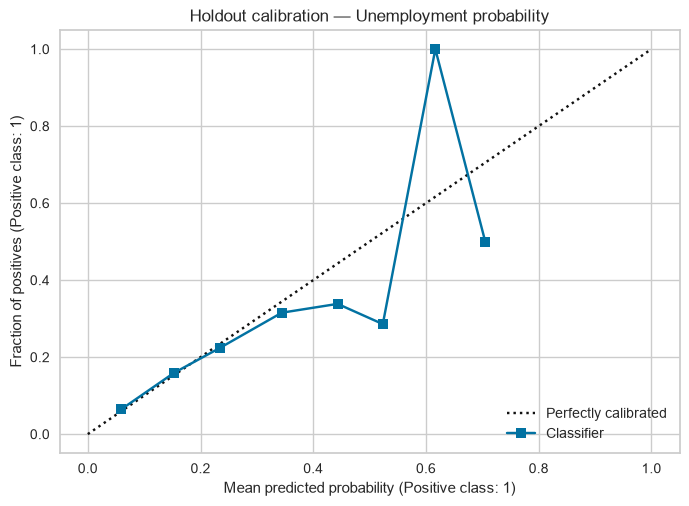

In [162]:
from sklearn.calibration import CalibrationDisplay
CalibrationDisplay.from_predictions(y_true, p_unemployed, n_bins=10)
plt.title("Holdout calibration — Unemployment probability")
plt.show()

### Read these three figures

**ROC:** For a random unemployed–employed pair, the AUC approximates how often the unemployed person is assigned a higher unemployment-risk score.  
**Precision–Recall:** Shows the trade-off when we identify more of the unemployed population.  
**Calibration:** A 0.30 predicted unemployment probability should correspond to about 30% unemployed among similarly scored people. Poor calibration may make estimated probabilities unsuitable for decisions, even with reasonable AUC.

## 13. Diagnostic score distribution and risk groups

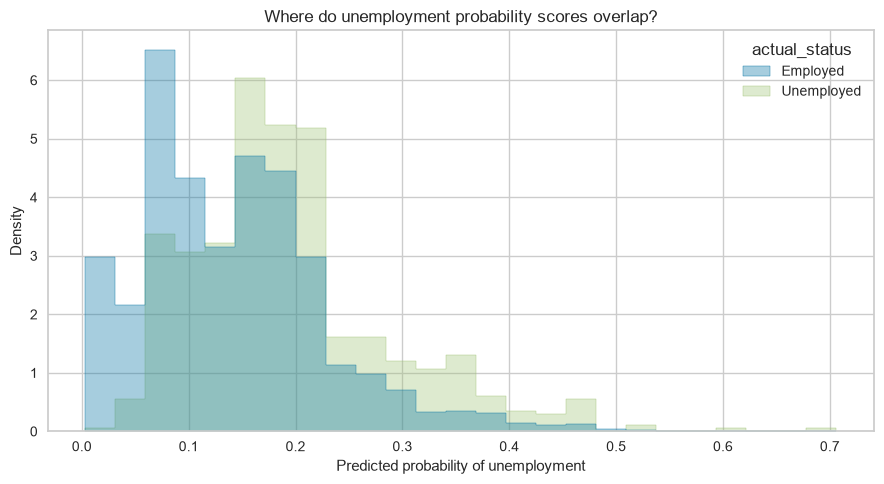

In [163]:
score_data = pd.DataFrame({
    "unemployment_probability": p_unemployed.to_numpy(),
    "actual_status": true_status.to_numpy()
})

plt.figure(figsize=(9, 5))
sns.histplot(
    data=score_data,
    x="unemployment_probability",
    hue="actual_status",
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.35
)
plt.title("Where do unemployment probability scores overlap?")
plt.xlabel("Predicted probability of unemployment")
plt.tight_layout()
plt.show()

In [164]:
# Descriptive risk groups, not a chosen policy threshold.
score_data["is_unemployed"] = (score_data["actual_status"] == "Unemployed").astype(int)
score_data["risk_group"] = pd.qcut(
    score_data["unemployment_probability"],
    q=10,
    duplicates="drop"
)

risk_summary = score_data.groupby("risk_group", observed=True).agg(
    people=("actual_status", "size"),
    observed_unemployment_rate=("is_unemployed", "mean"),
    mean_predicted_probability=("unemployment_probability", "mean")
)
display(risk_summary.round(3))

,people,observed_unemployment_rate,mean_predicted_probability
risk_group,,,
"(0.0021, 0.0498]",480,0.015,0.020
"(0.0498, 0.0708]",479,0.069,0.063
"(0.0708, 0.0889]",478,0.086,0.079
"(0.0889, 0.112]",489,0.119,0.101
"(0.112, 0.143]",471,0.138,0.128
"(0.143, 0.164]",482,0.154,0.155
"(0.164, 0.185]",475,0.213,0.174
"(0.185, 0.209]",481,0.173,0.196
"(0.209, 0.261]",475,0.227,0.227


If the highest-risk groups contain far more unemployed people than average, the model may be useful for ranking needs. **But:** showing a chart on holdout data must not be used to choose a new cutoff/model and then claim the same holdout is independent confirmation.

## 14. Inspect errors for different groups (exploratory fairness audit)

In [165]:
error_data = holdout.copy()
error_data["actual_unemployed"] = y_true.to_numpy()
error_data["predicted_unemployed"] = y_pred.to_numpy()
error_data["correct"] = (
    error_data["actual_unemployed"] == error_data["predicted_unemployed"]
).astype(int)
error_data["unemployed_found"] = (
    (error_data["actual_unemployed"] == 1) &
    (error_data["predicted_unemployed"] == 1)
).astype(int)

sex_results = error_data.groupby("sex", dropna=False).agg(
    number_of_people=("correct", "size"),
    accuracy=("correct", "mean"),
    unemployed_count=("actual_unemployed", "sum"),
    unemployed_correctly_found=("unemployed_found", "sum")
)
sex_results["unemployed_recall"] = (
    sex_results["unemployed_correctly_found"] /
    sex_results["unemployed_count"].replace(0, np.nan)
)
display(sex_results.round(3))

,number_of_people,accuracy,unemployed_count,unemployed_correctly_found,unemployed_recall
sex,,,,,
Female,2344,0.835,385,4,0.01
Male,2445,0.868,321,0,0.00


In [166]:
residence_results = error_data.groupby("residence", dropna=False).agg(
    number_of_people=("correct", "size"),
    accuracy=("correct", "mean"),
    unemployed_count=("actual_unemployed", "sum"),
    unemployed_correctly_found=("unemployed_found", "sum")
)
residence_results["unemployed_recall"] = (
    residence_results["unemployed_correctly_found"] /
    residence_results["unemployed_count"].replace(0, np.nan)
)
display(residence_results.round(3))

,number_of_people,accuracy,unemployed_count,unemployed_correctly_found,unemployed_recall
residence,,,,,
Rural,2938,0.842,463,3,0.006
Urban,1851,0.868,243,1,0.004


**Interpretation:** Check whether unemployed recall differs between women and men or between rural and urban youth. Small group sizes and clustering make these differences uncertain. This is **descriptive algorithmic performance**, not proof of discrimination or causes of unemployment. A credible fairness audit would also examine precision, error rates, calibration, and confidence intervals per group.

## 15. Optional uncertainty interval for unemployed recall

In [167]:
# Wilson binomial interval is illustrative only; it assumes independent observations.
# It does NOT account for the complex LFS survey design.
from statsmodels.stats.proportion import proportion_confint

if (tp + fn) > 0:
    recall_low, recall_high = proportion_confint(
        tp, tp + fn, alpha=0.05, method="wilson"
    )
    print(f"Unemployed recall: {tp / (tp + fn):.3f}")
    print(f"Illustrative 95% Wilson interval: [{recall_low:.3f}, {recall_high:.3f}]")
else:
    print("No unemployed cases in holdout; recall cannot be estimated.")

Unemployed recall: 0.006
Illustrative 95% Wilson interval: [0.002, 0.014]


**Careful:** With a complex household survey, a normal binomial interval may understate uncertainty. For a design-adjusted interval, preserve the survey's sampling units, strata, and weights and use suitable survey methods.

## 16. Optional: training-only hyperparameter tuning

This is a **new modeling experiment**, not necessary for the first diagnosis. If you decide to tune, do it on **training CV only**. Avoid looking at the holdout metrics repeatedly to choose your model. 

`optimize="AUC"` tunes ranking ability; `optimize="F1"` optimizes the built-in F1 score, whose positive-label convention you must check. Use explicit per-class metrics later to decide practical utility. **Leave these optional cells unrun until you have documented the untuned results.**

In [168]:
# OPTIONAL: train-only CV hyperparameter search; can be slow.
# Uncomment when ready:
# tuned_model = tune_model(best, optimize="AUC", n_iter=20, choose_better=True)
# display(pull())
# print(tuned_model)

## 17. Optional: probability threshold selection — keep it out of the test set

A 0.50 threshold is not necessarily appropriate for the minority class. **Do not find a threshold by maximizing F1 on the final holdout**—that would contaminate the holdout. PyCaret 3 provides `optimize_threshold()` for a training-side search. Verify which target class its built-in objective rewards; for our research, `Unemployed` recall matters. After the threshold is fixed using CV, you may evaluate it **once** on untouched holdout.

In [169]:
# OPTIONAL training-only threshold search (do not tune on holdout):
# threshold_model = optimize_threshold(best, optimize="F1", grid_interval=0.05)
# display(pull())
# new_holdout = predict_model(threshold_model, raw_score=True)
# Use the same manual class-specific metric code on the new holdout.
# Note: repeated holdout comparisons weaken claims of independent validation.

## 18. Optional: class imbalance sensitivity (separate experiment)

A second experiment can compare class weighting/SMOTE **inside training folds**. Do **not** perform resampling on the full dataset or before the train/holdout split. `fix_imbalance=True` may alter trade-offs and is not guaranteed to help.

To compare fairly, use the **same holdout split**, keep the originally reserved holdout intact, and choose models by training CV. A fresh `setup()` on the same data/seed is not automatically a fully controlled comparison for complex survey data. A dedicated grouped evaluation would be stronger.

In [170]:
# OPTIONAL — a separate PyCaret setup, not executed by default:
# imbalanced_exp = setup(
#     data=model_data, target="employment_status", session_id=123,
#     train_size=0.7, data_split_stratify=True,
#     fold=5, numeric_imputation="median",
#     categorical_imputation="mode", fix_imbalance=True
# )
# weighted_candidate = compare_models(include=["lr", "rf", "gbc"], sort="AUC")
# IMPORTANT: setup() resets the active PyCaret session; rerun prior setup to resume.

## 19. Optional PyCaret model interpretation

**Permutation importance** estimates how much the model's performance drops when a feature is shuffled. **SHAP** describes contributions to predictions. Both are **associational**. With highly correlated geography/education variables, individual importance can be unstable. Optional packages may be needed.

In [171]:
# OPTIONAL, can require extra packages and time:
# from pycaret.classification import interpret_model
# interpret_model(best, plot="pfi")
# plot_model(best, plot="feature_all")
# plot_model(best, plot="gain")
# plot_model(best, plot="lift")
# plot_model(best, plot="ks")

## 20. Save the evaluation outputs; do not finalize prematurely

In [172]:
# Holdout predictions for checking and writing the report.
# Beware that these are individual-level records; treat them as confidential.
holdout.to_csv("PyCaret_holdout_predictions_LOCAL_ONLY.csv", index=False)

print("Saved:")
print("- PyCaret_training_CV_comparison.csv")
print("- PyCaret_holdout_metrics.csv")
print("- PyCaret_holdout_predictions_LOCAL_ONLY.csv")

Saved:
- PyCaret_training_CV_comparison.csv
- PyCaret_holdout_metrics.csv
- PyCaret_holdout_predictions_LOCAL_ONLY.csv


### Model finalization (only AFTER selection and final independent evaluation)

Do **not** finalize for evaluation: `finalize_model()` refits using **both** training and holdout. It is suitable only after reporting the untouched-holdout results and deciding to build a deployment pipeline. Do not compute a new 'holdout test' after finalization.

```python
# OPTIONAL — not for model comparison
# final_model = finalize_model(best)
# save_model(final_model, "LFS2025_employment_classifier")
```

Never upload individual-level LFS predictions to a public repository without checking access and confidentiality permissions.

## 21. What to write in your PBL report

### Methods — sample paragraph structure

> We used the Rwanda Labour Force Survey 2025 to examine binary employment status among economically active young people aged 16–30. We excluded NEET status, job-specific characteristics, and income variables from predictors to avoid target leakage. The data were split into a stratified 70% training sample and a 30% holdout. Models were compared using five-fold cross-validation, with median/mode imputation within the preprocessing pipeline. We assessed predictive performance using ROC-AUC and minority-class-specific recall, precision and F1, supported by confusion matrices and calibration diagnostics.

### Results — numbers to fill in AFTER running

| Reporting item | What to copy |
|---|---|
| Training sample and class proportions | Section 6 |
| CV model leaderboard | Section 7 |
| Best AUC and its model | Section 7 |
| Untouched holdout accuracy | Section 11 |
| **Unemployed recall / precision / F1** | Section 11 |
| Confusion counts (TP, FN, FP, TN) | Section 11 |
| ROC-AUC and average precision | Section 11 |
| Calibration (Brier and chart) | Sections 11–12 |
| Differences by sex and residence | Section 14 |
| Key feature associations | Section 9 / optional Section 19 |
| Limitations | Missingness, unweighted design, clustering, cross-section |

### Discussion — the conclusion to test

- Does the chosen model actually detect more unemployed respondents than a majority-class baseline?
- Is the **false-negative rate** (unemployed people missed) acceptable for any proposed screening application?
- Are probability estimates calibrated, or is the model only moderately useful for ranking?
- Do the findings differ across sex, residence or education groups?
- How sensitive are results to how TVET and other missing values were handled?

**Never write:** “education causes unemployment” from feature importance, or “85% of Rwanda’s youth are employed” from the unweighted share of this labor-force-only dataset. Classifying employment status is not the same as estimating the national unemployment rate.

## 22. Metric formulas — quick reference

For **Unemployed = 1**:

\[
\text{Precision}=\frac{TP}{TP+FP},\qquad
\text{Recall}=\frac{TP}{TP+FN},\qquad
\text{Specificity}=\frac{TN}{TN+FP}
\]

\[
F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}},\qquad
\text{Balanced Accuracy}=\frac{\text{Recall}+\text{Specificity}}{2}
\]

\[
\text{FNR}=\frac{FN}{FN+TP},\qquad
\text{FPR}=\frac{FP}{FP+TN},\qquad
\text{NPV}=\frac{TN}{TN+FN}
\]

- **TP:** correctly flagged unemployed.
- **FN:** unemployed missed (most concerning for outreach).
- **FP:** employed incorrectly flagged.
- **TN:** employed correctly recognized.

**Interpretation warning:** Improving unemployed recall often lowers precision. Neither metric alone guarantees a useful social application.

## References

1. **NISR.** Rwanda Labour Force Survey 2025, [catalog and data dictionary](https://microdata.statistics.gov.rw/index.php/catalog/125/data-dictionary).  
2. **PyCaret 3.x.** [Classification API](https://pycaret.readthedocs.io/en/stable/api/classification.html): `setup`, `compare_models`, `predict_model`, `plot_model`, `tune_model`.  
3. **scikit-learn.** [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).  
4. **ILO / ILOSTAT.** [Unemployment and labour underutilization](https://ilostat.ilo.org/topics/unemployment-and-labour-underutilization/).

**Suggested next step:** Run Sections 1–8, then Sections 10–12. Share the **Unemployed precision/recall/F1, MCC, average precision, and confusion matrix** before writing the report.